In [1]:
#!pip install biopython pandas matplotlib seaborn pyarrow openpyxl umap-learn plotly

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import scipy as sp
import pandas as pd
import networkx as nx
import random
import matplotlib.pyplot as plt
# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)
from IPython.core.display import HTML
HTML('<style>.container { width:95% !important; }</style><style>.output_png {display: table-cell;text-align: center;vertical-align: middle;}</style>')

In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm

def plot_heatmap_for_pathogen(df, pathogen, class_df=None, log_scale=True, figsize=(12, 6), show_only_class=False):
    """
    Plot a heatmap of PMID counts for a given pathogen.

    Args:
        df (pd.DataFrame): Results dataframe with columns 
                           ["pathogen","antibiotic","start_date","end_date","count"].
        pathogen (str): Pathogen to visualize.
        class_df (pd.DataFrame, optional): Mapping DataFrame with columns 
                                           ["antibiotic","class"] (case-insensitive).
                                           If provided, antibiotics can be grouped by class.
        log_scale (bool): If True, apply logarithmic color scaling.
        figsize (tuple): Figure size.
        show_only_class (bool): 
            - If True, antibiotics are aggregated by class.
            - If False, antibiotics are shown individually, prefixed with their class.
    """
    sub = df[df["pathogen"].str.lower() == pathogen.lower()].copy()

    if sub.empty:
        print(f"No data for pathogen: {pathogen}")
        return

    # Compute midpoint of interval
    sub["year_mid"] = (
        (pd.to_datetime(sub["start_date"]).dt.year +
         pd.to_datetime(sub["end_date"]).dt.year) // 2 + 1
    )

    if class_df is not None:
        # Normalize mapping dataframe
        class_df = class_df.rename(columns={c: c.lower() for c in class_df.columns})
        if "antibiotic" not in class_df.columns or "class" not in class_df.columns:
            raise ValueError("class_df must contain 'antibiotic' and 'class' columns")

        # Lowercase antibiotics for consistent merge
        sub["antibiotic"] = sub["antibiotic"].str.lower()
        class_df["antibiotic"] = class_df["antibiotic"].str.lower()

        # Merge to add class info
        sub = sub.merge(class_df, on="antibiotic", how="left")

        # If class not found, fallback to antibiotic name
        sub["class"] = sub["class"].fillna(sub["antibiotic"])

        if show_only_class:
            # Aggregate by class
            sub = sub.groupby(["class", "year_mid"], as_index=False)["count"].sum()
            index_col = "class"
        else:
            # Prefix antibiotic with class for disambiguation
            sub["antibiotic_prefixed"] = sub["class"] + " | " + sub["antibiotic"]
            sub = sub.groupby(["antibiotic_prefixed", "year_mid"], as_index=False)["count"].sum()
            index_col = "antibiotic_prefixed"

    else:
        # No class info provided
        sub["class"] = sub["antibiotic"]
        index_col = "antibiotic"

    # Pivot to matrix
    pivot = sub.pivot(index=index_col, columns="year_mid", values="count").fillna(0)

    # Sort rows by total counts
    row_order = pivot.sum(axis=1).sort_values(ascending=False).index
    pivot = pivot.loc[row_order]

    # Define normalization
    norm = LogNorm(vmin=1, vmax=pivot.values.max()) if log_scale else None

    # Plot heatmap
    plt.figure(figsize=figsize)
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".0f",
        cmap="Reds",
        norm=norm,
        cbar_kws={"label": "PMID count (log scale)" if log_scale else "PMID count"}
    )
    plt.title(f"PubMed resistance reports for {pathogen}")
    plt.xlabel("Midpoint of interval")
    plt.ylabel("Antibiotic class" if show_only_class else "Antibiotic (prefixed by class)")
    plt.tight_layout()
    plt.show()


In [5]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import TwoSlopeNorm

def plot_heatmap_for_pathogen_debiased(
    df,
    pathogen,
    class_df=None,
    value="zscore",
    figsize=(12, 6),
    show_only_class=False,
    vmin=None,
    vmax=None,
):
    """
    Robust, diagnostic version — guaranteed not to crash on NaN/inf positions.
    """

    # --- 1. Filter pathogen ---
    sub = df[df["pathogen"].str.lower() == pathogen.lower()].copy()
    if sub.empty:
        print(f"No data for pathogen: {pathogen}")
        return

    if value not in sub.columns:
        raise ValueError(f"Column '{value}' not found in dataframe.")

    x_label = "Interval"
    interval_col = None
    resolver = globals().get("_resolve_interval_column")

    def _ensure_interval(df):
        nonlocal resolver
        if resolver is not None:
            return resolver(df)

        candidates = [("interval", "Interval"), ("decade", "Decade")]
        for col, label in candidates:
            if col in df.columns:
                return df, col, label

        if {"start_date", "end_date"}.issubset(df.columns):
            local = df.copy()
            start_year = pd.to_datetime(local["start_date"]).dt.year.astype("Int64")
            end_year = pd.to_datetime(local["end_date"]).dt.year.astype("Int64")
            local["_auto_interval"] = start_year.astype(str) + "-" + end_year.astype(str)
            return local, "_auto_interval", "Interval"

        raise ValueError("Unable to determine interval column; please run the helper cell defining _resolve_interval_column or include interval metadata.")

    # --- 2. Add antibiotic class if provided ---
    if class_df is not None:
        class_df = class_df.rename(columns={c: c.lower() for c in class_df.columns})
        sub["antibiotic"] = sub["antibiotic"].str.lower()
        class_df["antibiotic"] = class_df["antibiotic"].str.lower()
        sub = sub.merge(class_df, on="antibiotic", how="left")
        sub["class"] = sub["class"].fillna(sub["antibiotic"])
        sub, interval_col, x_label = _ensure_interval(sub)
        if show_only_class:
            sub = sub.groupby(["class", interval_col], as_index=False)[value].mean()
            index_col = "class"
        else:
            sub["antibiotic_prefixed"] = sub["class"] + " | " + sub["antibiotic"]
            sub = sub.groupby(["antibiotic_prefixed", interval_col], as_index=False)[value].mean()
            index_col = "antibiotic_prefixed"
    else:
        sub, interval_col, x_label = _ensure_interval(sub)
        index_col = "antibiotic"

    if interval_col is None:
        raise ValueError("Unable to determine interval column for plotting.")

    # --- 3. Clean numeric column ---
    sub[value] = pd.to_numeric(sub[value], errors="coerce").replace([np.inf, -np.inf], np.nan)
    sub = sub.dropna(subset=[value])

    # --- 4. Pivot and sanitize ---
    pivot = sub.pivot(index=index_col, columns=interval_col, values=value)
    pivot = pivot.replace([np.inf, -np.inf], np.nan).fillna(0.0)

    # remove any non-string index labels that could cause tick NaN
    pivot.index = pivot.index.astype(str)
    pivot.columns = [str(c) for c in pivot.columns]

    # --- 5. Verify finiteness ---
    if not np.all(np.isfinite(pivot.values)):
        print("⚠️ Non-finite entries detected, replacing with 0.")
        pivot = np.nan_to_num(pivot.values)
        pivot = pd.DataFrame(pivot)

    # Drop empty rows
    if isinstance(pivot, pd.DataFrame):
        pivot = pivot.loc[pivot.sum(axis=1) != 0]
    if pivot.empty:
        print("No finite values left to plot.")
        return

    # --- 6. Sort and normalize ---
    if isinstance(pivot, pd.DataFrame):
        row_order = pivot.abs().sum(axis=1).sort_values(ascending=False).index
        pivot = pivot.loc[row_order]

    vmax_auto = float(np.nanmax(np.abs(pivot.values)))
    if not np.isfinite(vmax_auto) or vmax_auto == 0:
        print("No finite range to plot.")
        return
    if vmin is None or vmax is None:
        vmin, vmax = -vmax_auto, vmax_auto
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

    # --- 7. Safety checks before plotting ---
    if not np.all(np.isfinite(pivot.values)):
        print("Non-finite data remain, skipping plot.")
        return
    if any(pd.isna(pivot.columns)) or any(pd.isna(pivot.index)):
        print("Non-finite tick labels, skipping plot.")
        return

    # --- 8. Plot ---
    plt.figure(figsize=figsize)
    sns.heatmap(
        pivot,
        cmap="RdBu_r",
        norm=norm,
        cbar_kws={"label": f"{value} (detrended)"},
        linewidths=0.3,
    )
    plt.title(f"Debiased {value} heatmap for {pathogen}")
    plt.xlabel(x_label)
    plt.ylabel("Antibiotic class" if show_only_class else "Antibiotic (prefixed by class)")
    plt.tight_layout()
    plt.show()




In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import TwoSlopeNorm


def _format_count_annotation(count_mat, expected_mat):
    observed = np.round(count_mat).astype(int).astype(str)
    expected = np.round(expected_mat).astype(int).astype(str)
    return observed + ":" + expected


def _resolve_interval_column(df):
    """Ensure an interval column is present and return metadata for plotting."""
    interval_candidates = [
        ("interval_label", "Interval"),
        ("interval", "Interval"),
        ("time_interval", "Time interval"),
        ("time_period", "Time period"),
        ("period", "Period"),
        ("year_interval", "Year interval"),
        ("year_bin", "Year bin"),
        ("decade", "Decade"),
    ]
    for column, axis_label in interval_candidates:
        if column in df.columns:
            return df, column, axis_label

    if {"start_date", "end_date"}.issubset(df.columns):
        df = df.copy()
        start_year = pd.to_datetime(df["start_date"]).dt.year.astype("Int64")
        end_year = pd.to_datetime(df["end_date"]).dt.year.astype("Int64")
        df["_interval_label"] = start_year.astype(str) + "-" + end_year.astype(str)
        return df, "_interval_label", "Interval"

    available = ", ".join(sorted(df.columns))
    candidate_names = [col for col, _ in interval_candidates]
    raise ValueError(
        "Unable to infer interval column; expected one of "
        f"{candidate_names} or 'start_date'/'end_date'. Available columns: {available}"
    )


def _plot_diff_heatmap(sub, index_col, interval_col, x_label, figsize, vmin, vmax, title):
    diff_mat = sub.pivot(index=index_col, columns=interval_col, values="diff").fillna(0.0)
    count_mat = sub.pivot(index=index_col, columns=interval_col, values="count").fillna(0.0)
    expected_mat = sub.pivot(index=index_col, columns=interval_col, values="expected_count").fillna(0.0)

    if diff_mat.empty:
        print("No data available for the requested selection.")
        return

    max_abs = np.nanmax(np.abs(diff_mat.values))
    if not np.isfinite(max_abs) or max_abs == 0:
        print("No variation in residuals to plot.")
        return

    if vmin is None or vmax is None:
        vmin, vmax = -max_abs, max_abs

    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    annot = _format_count_annotation(count_mat, expected_mat)

    plt.figure(figsize=figsize)
    sns.heatmap(
        diff_mat,
        cmap="RdBu_r",
        norm=norm,
        cbar_kws={"label": "log residual (observed - expected)"},
        annot=annot,
        fmt="",
        linewidths=0.3,
        linecolor="grey",
    )
    plt.title(title)
    plt.xlabel(x_label)
    plt.tight_layout()
    plt.show()


# --------------------------------------------------------------------
# ANTIBIOTIC-LEVEL HEATMAP
# --------------------------------------------------------------------
def plot_heatmap_counts_vs_expected_antibiotic(
    df,
    pathogen,
    class_df=None,
    figsize=(12, 6),
    vmin=None,
    vmax=None,
):
    """Plot pathogen vs antibiotic heatmap using marginal debiasing residuals."""
    sub = df[df["pathogen"].str.lower() == pathogen.lower()].copy()
    if sub.empty:
        print(f"No data for pathogen: {pathogen}")
        return

    if class_df is not None:
        mapper = class_df.rename(columns={c: c.lower() for c in class_df.columns}).copy()
        mapper["antibiotic"] = mapper["antibiotic"].str.lower()
        sub["antibiotic"] = sub["antibiotic"].str.lower()
        sub = sub.merge(mapper, on="antibiotic", how="left")
        sub["class"] = sub["class"].fillna(sub["antibiotic"])
        sub["antibiotic_prefixed"] = sub["class"] + " | " + sub["antibiotic"]
        index_col = "antibiotic_prefixed"
    else:
        index_col = "antibiotic"

    sub, interval_col, x_label = _resolve_interval_column(sub)
    title = (
        f"{pathogen}: observed vs expected counts per {x_label.lower()} (antibiotic-level)"
    )
    _plot_diff_heatmap(sub, index_col, interval_col, x_label, figsize, vmin, vmax, title)


# --------------------------------------------------------------------
# CLASS-LEVEL HEATMAP
# --------------------------------------------------------------------
def plot_heatmap_counts_vs_expected_class(
    df,
    pathogen,
    figsize=(10, 5),
    vmin=None,
    vmax=None,
    class_column="class",
    class_df=None,
):
    """Plot pathogen vs group heatmap using marginal debiasing residuals."""
    sub = df[df["pathogen"].str.lower() == pathogen.lower()].copy()
    if sub.empty:
        print(f"No data for pathogen: {pathogen}")
        return

    if not isinstance(class_column, str) or not class_column.strip():
        raise ValueError("class_column must be a non-empty string.")

    requested_key = class_column.strip().lower()
    sub_lookup = {col.lower(): col for col in sub.columns}
    resolved_col = sub_lookup.get(requested_key)

    if resolved_col is None:
        if class_df is None:
            available = ", ".join(sorted(sub.columns))
            raise ValueError(
                f"Column '{class_column}' not found in dataframe. Available columns: {available}"
            )

        mapper = class_df.rename(columns={c: c.lower() for c in class_df.columns}).copy()
        if "class" not in mapper.columns:
            raise ValueError("class_df must contain a 'Class' column for mapping.")
        mapper["class"] = mapper["class"].str.lower()

        mapper_lookup = {col.lower(): col for col in mapper.columns}
        mapped_col = mapper_lookup.get(requested_key)
        if mapped_col is None:
            available = ", ".join(sorted(class_df.columns))
            raise ValueError(
                f"Column '{class_column}' not found in class_df. Available columns: {available}"
            )

        mapping_series = (
            mapper[["class", mapped_col]]
            .dropna(subset=[mapped_col])
            .drop_duplicates(subset=["class"])
            .set_index("class")[mapped_col]
        )
        target_col = class_column if class_column not in sub.columns else f"{class_column}_mapped"
        match_key = sub["class"].str.lower()
        sub[target_col] = match_key.map(mapping_series).fillna(sub["class"])
        resolved_col = target_col
    else:
        target_col = resolved_col

    sub, interval_col, x_label = _resolve_interval_column(sub)

    group_cols = ["pathogen", resolved_col, interval_col]
    if not set(["count", "expected_count"]).issubset(sub.columns):
        missing = sorted({"count", "expected_count"} - set(sub.columns))
        raise ValueError(
            f"Dataframe is missing required columns for aggregation: {missing}"
        )
    aggregated = (
        sub.groupby(group_cols, as_index=False)[["count", "expected_count"]]
        .sum()
    )
    aggregated["log_count"] = np.log1p(aggregated["count"])
    aggregated["expected_log"] = np.log1p(aggregated["expected_count"])
    aggregated["diff"] = aggregated["log_count"] - aggregated["expected_log"]
    sub = aggregated
    friendly_group = class_column.replace("_", " ").strip() or class_column
    title = (
        f"{pathogen}: observed vs expected counts per "
        f"{x_label.lower()} ({friendly_group} level)"
    )
    _plot_diff_heatmap(sub, resolved_col, interval_col, x_label, figsize, vmin, vmax, title)



---

In [7]:
data_df = pd.read_parquet("data.parquet")
data_df

,Genus,CanonicalSpecies,n_causation,n_articles,n_sampled,pathogenic_index,embedding,anonymised_embedding,onehot_embedding,domain,kingdom,phylum,class,order,family
0,Abiotrophia,Abiotrophia defectiva,6,6,6,0.160939,"[0.018194107338786125, -0.004734894765230517, ...","[0.014040807844139636, -0.028420374651129048, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.166...",Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Aerococcaceae
1,Acetobacter,Acetobacter indonesiensis,1,3,3,0.000000,"[-0.021512236446142197, -0.03992129862308502, ...","[-0.0028289835900068283, -0.04833690822124481,...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
2,Acetobacter,Acetobacter tropicalis,1,2,2,0.000000,"[-0.0070418259128928185, -0.005829853471368551...","[0.005147432442754507, -0.013049994595348835, ...","[0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
3,Achromobacter,Achromobacter animicus,1,2,2,0.000000,"[0.011074555106461048, 0.013332720845937729, 0...","[0.012643104419112206, -0.01178667601197958, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
4,Achromobacter,Achromobacter denitrificans,75,36,36,0.387804,"[0.014773702074987037, -0.004635852294159122, ...","[0.011467029051855206, -0.012983008560258896, ...","[0.04, 0.013333333333333334, 0.066666666666666...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1274,Yersinia,Yersinia enterocolitica,85,3419,200,0.654031,"[-0.009990866917788105, 0.009774883079979405, ...","[0.0024005417033656747, -0.009907858140479005,...","[0.0, 0.0, 0.0, 0.03529411764705882, 0.0, 0.0,...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1275,Yersinia,Yersinia frederiksenii,1,21,21,0.000000,"[-0.00901515781879425, 0.02502085641026497, 0....","[0.01804814115166664, 0.005011445842683315, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1276,Yersinia,Yersinia pestis,124,2184,200,0.647694,"[-0.006688895473886195, 0.014983039929487154, ...","[0.011833864605177364, -0.0048193380043226024,...","[0.0, 0.0, 0.0, 0.016129032258064516, 0.0, 0.0...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1277,Yersinia,Yersinia pseudotuberculosis,88,1234,200,0.565611,"[-0.01641193700528344, 0.008593090970448842, 0...","[0.004612311640316461, -0.005791128928070644, ...","[0.011363636363636364, 0.0, 0.0113636363636363...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae


In [8]:
antibiotics_df = pd.read_excel("antibiotic_list2.xlsx")
for col in antibiotics_df.columns:
    col_list = antibiotics_df[col].values
    print(f'#{col}: {len(set(col_list))}')
antibiotics_df.head()

#Antibiotic: 245
#Class: 40
#Simplified categories: 16
#High level categories: 12
#Origin: 2


,Antibiotic,Class,Simplified categories,High level categories,Origin
0,Amikacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
1,Arbekacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
2,Bekanamycin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
3,Dibekacin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
4,Gentamicin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified


In [9]:
amr_df = pd.read_parquet("pmids_results.parquet")
amr_df

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram
0,Abiotrophia defectiva,Spectinomycin,1975/01/01,1979/12/31,[],0,{}
1,Abiotrophia defectiva,Spectinomycin,1980/01/01,1984/12/31,[],0,{}
2,Abiotrophia defectiva,Spectinomycin,1985/01/01,1989/12/31,[],0,{}
3,Abiotrophia defectiva,Spectinomycin,1990/01/01,1994/12/31,[],0,{}
4,Abiotrophia defectiva,Spectinomycin,1995/01/01,1999/12/31,[],0,{}
...,...,...,...,...,...,...,...
1893845,Yokenella regensburgei,Trimethoprim,2000/01/01,2004/12/31,[],0,{}
1893846,Yokenella regensburgei,Trimethoprim,2005/01/01,2009/12/31,[],0,{}
1893847,Yokenella regensburgei,Trimethoprim,2010/01/01,2014/12/31,[],0,{}
1893848,Yokenella regensburgei,Trimethoprim,2015/01/01,2019/12/31,[],0,{}


### Debiasing via marginal interval profiles

We estimate expected resistance signal for each pathogen–antibiotic pair by isolating how each antibiotic behaves across intervals.

1. Assign every interval to a interval and compute log-damped counts
   $$L_{p,a,t} = \log(1 + C_{p,a,t}).$$
2. Aggregate the log counts across pathogens for each antibiotic (or class) to obtain its interval profile. Normalise this profile so it sums to one — this captures the typical interval distribution for that antibiotic.
3. Sum the interval-level log counts for each pathogen–antibiotic pair to obtain the total log signal
   $$L^{\text{tot}}_{p,a} = \sum_t L_{p,a,t},$$
   which reflects how much attention that pair receives overall after damping spikes.
4. Allocate the total log signal back to intervals using the antibiotic's marginal profile to obtain the expected log signal
   $$\hat{L}_{p,a,t} = L^{\text{tot}}_{p,a} \times P_{a,t}.$$
5. Convert the expected log signal to the count scale with
   $$\exp(\hat{L}_{p,a,t}) - 1$$
   to obtain the expected publication count per interval.
6. Analyse the log-space residuals
   $$R_{p,a,t} = L_{p,a,t} - \hat{L}_{p,a,t}$$
   to highlight intervals where the pair appears more or less often than the antibiotic's historical pattern suggests.

In the heatmaps we annotate each cell with the observed and expected counts, and colour by the residual in log space.




In [10]:

import pandas as pd
import numpy as np


def _infer_interval_span(start_year, end_year):
    """Infer the most common inclusive interval span from the data."""
    spans = (end_year - start_year).dropna() + 1
    spans = spans[spans > 0]
    if spans.empty:
        return None
    mode = spans.mode()
    if mode.empty:
        return None
    return int(mode.iloc[0])


def _label_interval(start_year, end_year, span_years=None, method="end"):
    """Assign an interval label using the specified method and span."""
    if pd.isna(start_year) or pd.isna(end_year):
        return None

    start_year = int(start_year)
    end_year = int(end_year)

    if span_years is None or span_years <= 0:
        label_start = start_year
        label_end = end_year
    else:
        span_years = int(span_years)
        if span_years <= 0:
            raise ValueError("span_years must be positive when provided.")

        if method == "end":
            anchor = end_year
            label_start = (anchor // span_years) * span_years
        elif method == "start":
            anchor = start_year
            label_start = (anchor // span_years) * span_years
        elif method == "midpoint":
            mid = (start_year + end_year) / 2.0
            label_start = (int(mid) // span_years) * span_years
        elif method == "max_overlap":
            d0 = (start_year // span_years) * span_years
            d1 = (end_year // span_years) * span_years
            best_start, best_len = d0, -1
            for d in range(d0, d1 + span_years, span_years):
                seg_start = max(start_year, d)
                seg_end = min(end_year, d + span_years - 1)
                overlap = max(0, seg_end - seg_start + 1)
                if overlap > best_len:
                    best_len, best_start = overlap, d
            label_start = best_start
        else:
            raise ValueError("method must be one of {'end','start','midpoint','max_overlap'}")

        label_end = label_start + span_years - 1
        start_year, end_year = label_start, label_end

    return f"{start_year}-{end_year}"



In [11]:
def _compute_marginal_distribution(df, key_col):
    """Return marginal log-count distribution per interval for a given key."""
    group_cols = [key_col, "interval"]
    marginal = (
        df.groupby(group_cols, as_index=False)["count"].sum()
          .rename(columns={"count": "count_sum"})
    )
    marginal["marginal_log"] = np.log1p(marginal["count_sum"])
    marginal["total_marginal_log"] = marginal.groupby(key_col)["marginal_log"].transform("sum")
    marginal["marginal_prob"] = np.where(
        marginal["total_marginal_log"] > 0,
        marginal["marginal_log"] / marginal["total_marginal_log"],
        0.0,
    )
    return marginal[[key_col, "interval", "marginal_prob", "marginal_log", "total_marginal_log"]]


def _prepare_pairwise_interval_counts(df, key_col):
    group_cols = ["pathogen", key_col, "interval"]
    pairwise = df.groupby(group_cols, as_index=False)["count"].sum()
    pairwise["log_count"] = np.log1p(pairwise["count"])
    pairwise["total_count"] = pairwise.groupby(["pathogen", key_col])["count"].transform("sum")
    pairwise["total_log_count"] = np.log1p(pairwise["total_count"])
    return pairwise


def debias_amr_marginal(amr_df, class_df, interval_method="end", interval_years=None):
    """Compute marginal log-scale debiasing for antibiotic and class levels."""
    df = amr_df.copy()
    df["antibiotic"] = df["antibiotic"].str.lower()

    start_year = pd.to_datetime(df["start_date"]).dt.year
    end_year = pd.to_datetime(df["end_date"]).dt.year
    interval_span = interval_years or _infer_interval_span(start_year, end_year)
    if interval_span is None:
        interval_span = 10

    df["interval"] = [
        _label_interval(s, e, span_years=interval_span, method=interval_method)
        for s, e in zip(start_year, end_year)
    ]
    df["log_count"] = np.log1p(df["count"])

    # Antibiotic level
    ab_marginal = _compute_marginal_distribution(df, "antibiotic")
    ab_counts = _prepare_pairwise_interval_counts(df, "antibiotic")
    ab_totals = ab_counts[["pathogen", "antibiotic", "total_count", "total_log_count"]].drop_duplicates()

    ab_full = ab_totals.merge(
        ab_marginal[["antibiotic", "interval", "marginal_prob"]],
        on="antibiotic",
        how="left",
    )
    ab_full = ab_full.merge(
        ab_counts[["pathogen", "antibiotic", "interval", "count", "log_count"]],
        on=["pathogen", "antibiotic", "interval"],
        how="left",
    )

    ab_full["count"] = ab_full["count"].fillna(0.0)
    ab_full["log_count"] = ab_full["log_count"].fillna(np.log1p(ab_full["count"]))
    ab_full["marginal_prob"] = ab_full["marginal_prob"].fillna(0.0)

    ab_full["expected_count"] = ab_full["total_count"] * ab_full["marginal_prob"]
    ab_full["expected_log"] = np.log1p(ab_full["expected_count"])
    ab_full["diff"] = ab_full["log_count"] - ab_full["expected_log"]

    ab_full = ab_full[
        [
            "pathogen",
            "antibiotic",
            "interval",
            "count",
            "log_count",
            "total_count",
            "total_log_count",
            "marginal_prob",
            "expected_log",
            "expected_count",
            "diff",
        ]
    ]

    # Class level
    class_df = class_df.rename(columns={c: c.lower() for c in class_df.columns}).copy()
    class_df["antibiotic"] = class_df["antibiotic"].str.lower()
    df_class = df.merge(class_df, on="antibiotic", how="left")
    df_class["class"] = df_class["class"].fillna(df_class["antibiotic"])

    cl_marginal = _compute_marginal_distribution(df_class, "class")
    cl_counts = _prepare_pairwise_interval_counts(df_class, "class")
    cl_totals = cl_counts[["pathogen", "class", "total_count", "total_log_count"]].drop_duplicates()

    cl_full = cl_totals.merge(
        cl_marginal[["class", "interval", "marginal_prob"]],
        on="class",
        how="left",
    )
    cl_full = cl_full.merge(
        cl_counts[["pathogen", "class", "interval", "count", "log_count"]],
        on=["pathogen", "class", "interval"],
        how="left",
    )

    cl_full["count"] = cl_full["count"].fillna(0.0)
    cl_full["log_count"] = cl_full["log_count"].fillna(np.log1p(cl_full["count"]))
    cl_full["marginal_prob"] = cl_full["marginal_prob"].fillna(0.0)

    cl_full["expected_count"] = cl_full["total_count"] * cl_full["marginal_prob"]
    cl_full["expected_log"] = np.log1p(cl_full["expected_count"])
    cl_full["diff"] = cl_full["log_count"] - cl_full["expected_log"]

    cl_full = cl_full[
        [
            "pathogen",
            "class",
            "interval",
            "count",
            "log_count",
            "total_count",
            "total_log_count",
            "marginal_prob",
            "expected_log",
            "expected_count",
            "diff",
        ]
    ]

    return ab_full, cl_full



def _build_pathogen_vectors(marg_df, key_col):
    """Convert marginal debiasing results into pathogen vectors.

    Pathogens are sorted alphabetically; columns iterate over the sorted set of
    `key_col` values and intervals, producing a consistent flattening order.
    Returns numpy arrays for pathogen names, total log counts, and the residual matrix.
    """
    if marg_df.empty:
        pathogens = []
        keys = []
        intervals = []
    else:
        pathogens = sorted(marg_df["pathogen"].dropna().unique())
        keys = sorted(marg_df[key_col].dropna().unique())
        intervals = sorted(marg_df["interval"].dropna().unique())

    if keys and intervals:
        combination_index = pd.MultiIndex.from_product([keys, intervals], names=[key_col, "interval"])
    else:
        combination_index = pd.MultiIndex.from_arrays([[], []], names=[key_col, "interval"])

    vectors = []
    totals = []
    for pathogen in pathogens:
        sub = (
            marg_df[marg_df["pathogen"] == pathogen]
            .set_index([key_col, "interval"])[["log_count", "expected_log"]]
            .reindex(combination_index, fill_value=0.0)
        )
        total_log = sub["log_count"].sum()
        totals.append(total_log)
        norm_log = sub["log_count"] / total_log if total_log > 0 else sub["log_count"]
        expected_total = sub["expected_log"].sum()
        norm_expected = sub["expected_log"] / expected_total if expected_total > 0 else sub["expected_log"]
        residual = norm_log - norm_expected
        vectors.append(residual.to_numpy())

    matrix = np.array(vectors) if vectors else np.empty((0, len(combination_index)))
    return np.array(pathogens), np.array(totals), matrix


def build_pathogen_vectors_antibiotic(amr_df, class_df, interval_method="end", interval_years=None):
    """Return pathogen vectors using antibiotic-level marginal debiasing."""
    marg_ab, _ = debias_amr_marginal(
        amr_df, class_df, interval_method=interval_method, interval_years=interval_years
    )
    return _build_pathogen_vectors(marg_ab, "antibiotic")


def build_pathogen_vectors_class(amr_df, class_df, interval_method="end", interval_years=None):
    """Return pathogen vectors using class-level marginal debiasing."""
    _, marg_cl = debias_amr_marginal(
        amr_df, class_df, interval_method=interval_method, interval_years=interval_years
    )
    return _build_pathogen_vectors(marg_cl, "class")





from umap import UMAP
import plotly.express as px


def _extract_genus(names):
    return [name.split()[0] if isinstance(name, str) and name else "Unknown" for name in names]


def _resolve_color_sequence(color_map, n_categories):
    """Return a color list sized for the number of categories."""
    if isinstance(color_map, (list, tuple)):
        sequence = list(color_map)
    elif isinstance(color_map, str):
        sequence = None
        for palette_module in (px.colors.qualitative, px.colors.sequential, px.colors.diverging):
            palette = getattr(palette_module, color_map, None)
            if palette is not None:
                sequence = list(palette)
                break
        if sequence is None:
            from plotly.colors import sample_colorscale
            effective = max(1, n_categories)
            positions = np.linspace(0, 1, effective) if effective > 1 else [0.5]
            sequence = sample_colorscale(color_map, positions)
    else:
        raise ValueError("color_map must be a string or a sequence of colors.")

    if not sequence:
        raise ValueError(f"Unrecognized color_map '{color_map}'.")

    effective = max(1, n_categories)
    base_len = len(sequence)
    if base_len < effective:
        chunk_size = (effective + base_len - 1) // base_len
        expanded = []
        for color in sequence:
            expanded.extend([color] * chunk_size)
            if len(expanded) >= effective:
                break
        sequence = expanded[:effective]
    else:
        sequence = sequence[:effective]
    return sequence

def _umap_scatter(
    pathogen_names,
    log_sums,
    vectors,
    title,
    marker_max_size=50,
    figure_size=(800, 600),
    color_map="Rainbow",
    min_size=0.0,
):
    """Create a 2D UMAP scatter plot with configurable presentation options."""
    vectors = np.asarray(vectors)
    if vectors.size == 0:
        raise ValueError("Input vectors are empty; compute pathogen vectors first.")
    if vectors.ndim != 2:
        raise ValueError("vectors must be a 2D array.")

    log_sums = np.asarray(log_sums, dtype=float)
    pathogen_names = np.asarray(pathogen_names)
    if log_sums.shape[0] != vectors.shape[0] or pathogen_names.shape[0] != vectors.shape[0]:
        raise ValueError("pathogen_names, log_sums, and vectors must align on the first dimension.")

    marker_max_size = float(marker_max_size)
    if marker_max_size <= 0:
        raise ValueError("marker_max_size must be greater than zero.")

    min_size = float(min_size)
    if min_size < 0:
        raise ValueError("min_size must be zero or positive.")

    mask = log_sums >= min_size
    if not np.any(mask):
        raise ValueError("No data points remain after applying min_size filter.")
    if not np.all(mask):
        log_sums = log_sums[mask]
        pathogen_names = pathogen_names[mask]
        vectors = vectors[mask]

    reducer = UMAP(n_components=2, random_state=42)
    embedding = reducer.fit_transform(vectors)

    pathogen_names = pathogen_names.tolist()
    genus = _extract_genus(pathogen_names)
    hover_names = pathogen_names

    marker_min_size = 1e-3
    marker_min_size = min(marker_min_size, marker_max_size)
    if log_sums.size > 0 and np.max(log_sums) > 0 and marker_max_size > marker_min_size:
        marker_sizes = (
            (log_sums / np.max(log_sums)) * (marker_max_size - marker_min_size) + marker_min_size
        )
    else:
        marker_sizes = np.full(log_sums.shape, marker_min_size, dtype=float)

    n_categories = len(set(genus))
    color_sequence = _resolve_color_sequence(color_map, n_categories)

    if figure_size is None:
        width, height = 600, 600
    elif isinstance(figure_size, (int, float)):
        width = height = int(figure_size)
    else:
        try:
            width, height = figure_size
        except (TypeError, ValueError):
            raise ValueError("figure_size must be a number or a (width, height) tuple.")
        width, height = int(width), int(height)

    if width <= 0 or height <= 0:
        raise ValueError("figure_size dimensions must be positive.")

    fig = px.scatter(
        x=embedding[:, 0],
        y=embedding[:, 1],
        color=genus,
        size=marker_sizes.tolist(),
        hover_name=hover_names,
        title=title,
        color_discrete_sequence=color_sequence,
    )
    fig.update_layout(
        xaxis=dict(visible=False, showgrid=False, zeroline=False),
        yaxis=dict(visible=False, showgrid=False, zeroline=False),
        legend_title="Genus",
        paper_bgcolor="white",
        plot_bgcolor="white",
        width=width,
        height=height,
    )
    fig.update_traces(marker=dict(line=dict(width=0.5, color="black"), sizemode="area"))
    return fig






In [12]:
marg_ab, marg_cl = debias_amr_marginal(amr_df, antibiotics_df)


### Pathogen vector representations

The helpers below compress each pathogen into a normalised log-residual vector
at the antibiotic and class levels, alongside total log-count weights.


In [13]:
pathogen_names_ab, pathogen_log_sums_ab, pathogen_vectors_ab = build_pathogen_vectors_antibiotic(
    amr_df,
    antibiotics_df,
)

pathogen_names_cl, pathogen_log_sums_cl, pathogen_vectors_cl = build_pathogen_vectors_class(
    amr_df,
    antibiotics_df,
)

pathogen_vectors_ab.shape, pathogen_vectors_cl.shape



((773, 2450), (773, 400))

(array([603.,  64.,  36.,  14.,   6.,  10.,   5.,   2.,   6.,   3.,   1.,
          2.,   2.,   0.,   2.,   2.,   3.,   1.,   2.,   2.,   0.,   0.,
          0.,   0.,   1.,   1.,   0.,   0.,   0.,   0.,   1.,   1.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   2.]),
 array([   0.        ,   72.22844643,  144.45689286,  216.68533928,
         288.91378571,  361.14223214,  433.37067857,  505.599125  ,
         577.82757142,  650.05601785,  722.28446428,  794.51291071,
         866.74135713,  938.96980356, 1011.19824999, 1083.42669642,
        1155.65514285, 1227.88358927, 1300.1120357 , 1372.34048213,
        1444.56892856, 1516.79737499, 1589.02582141, 1661.25426784,
        1733.48271427, 1805.7111607 , 1877.93960713, 1950.16805355,
        2022.39649998, 2094.62494641, 2166.85339284, 2239.08183926,
        2311.31028569, 2383.53873212, 2455.76717855, 2527.99562498,
        2600.2240714 , 2672.45251783, 2744.680

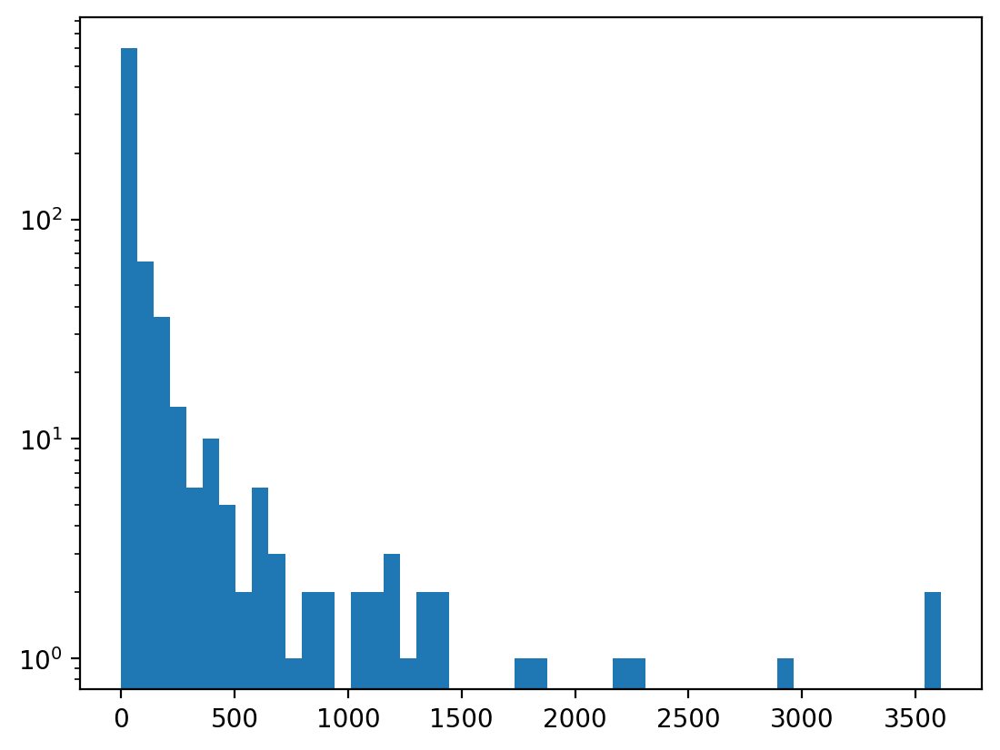

In [14]:
plt.hist(pathogen_log_sums_ab,50, log=True)

### UMAP scatter plots

Two-dimensional UMAP projections for antibiotic and class vectors, coloured by pathogen genus.


# Todo

- select time for plot
- plot by raw numbers
- plot xy by old similarity , color by antibiotic/class in time interval, make a row of plots by time

In [15]:
fig_ab = _umap_scatter(
    pathogen_names_ab,
    pathogen_log_sums_ab,
    pathogen_vectors_ab,
    title="UMAP projection of pathogens (antibiotic space)",
    marker_max_size=10,
    figure_size=(800, 600),
    color_map="Rainbow",
    min_size=50.0,
)
fig_ab



In [16]:
fig_cl = _umap_scatter(
    pathogen_names_cl,
    pathogen_log_sums_cl,
    pathogen_vectors_cl,
    title="UMAP projection of pathogens (class space)",
    min_size=0.0,
)
fig_cl



### Next steps: forecasting counts from embeddings

**Goal:** produce pathogen–antibiotic (and class-level) count forecasts for a future decade by combining forecasts of global antibiotic behaviour with pathogen-specific residual structure, while denormalising using observed totals from training.

1. **Forecast antibiotic/class marginal profiles.**  Fit a simple linear trend (or polynomial with regularisation) on each antibiotic’s decade-wise marginal signal $P_{a,t}$ to extrapolate $P_{a,t+1}$.  We treat these projections as scaled intensity factors rather than probabilities, so no renormalisation step is required even if total mass shifts.
2. **Assemble training targets in normalised form.**  Continue using the residual embeddings (normalised log differences) derived from observed data so the model learns deviations relative to the historical marginal behaviour.
3. **Model pathogen residual vectors.**  Train a gradient-boosted model (e.g. LightGBM/XGBoost) that consumes a window of the past $k$ decades (concatenated embeddings, optional covariates) and predicts the residual pattern for the next decade $R_{p,a,t+1}$.  Because the data are detrended, learning joint temporal patterns across pathogens should generalise across periods.
4. **Reconstruct predicted log signals.**  Combine the extrapolated marginal scale and the predicted residuals to produce normalised log values for the future decade.  Instead of forecasting new totals, re-introduce scale by multiplying with the observed totals from the latest available decade (or another chosen reference).
5. **Recover counts.**  Apply $\exp(\hat{L}_{p,a,t+1}) - 1$ to obtain count estimates, clip negatives, and optionally round.  Because we anchored to historical totals, the resulting sums reflect past magnitude while accommodating new marginal trends.

**Implementation plan:**
- Build decade-wise panels for antibiotic/class marginals, pathogen totals, and residual embeddings (training features/targets).
- Prototype the linear-trend extrapolators (`numpy.polyfit`/`LinearRegression`) for the marginal signals; inspect whether extrapolated values remain in plausible ranges without renormalisation.
- Train and validate gradient-boosted models that take $k$-decade windows of residual embeddings (plus metadata) and predict the next-decade residuals; tune $k$ and feature engineering for best generalisation.
- Integrate the reconstruction workflow that reuses observed totals for de-normalisation; back-test on held-out decades to measure reconstruction error relative to ground truth counts.
- Package the pipeline into reusable helpers/notebook cells to enable rapid experimentation with alternative temporal models or denormalisation baselines.



In [17]:
pathogen = 'Staphylococcus aureus'

In [ ]:
pathogen = 'Neisseria gonorrhoeae'

In [ ]:
pathogen = 'Mycobacterium senegalense'

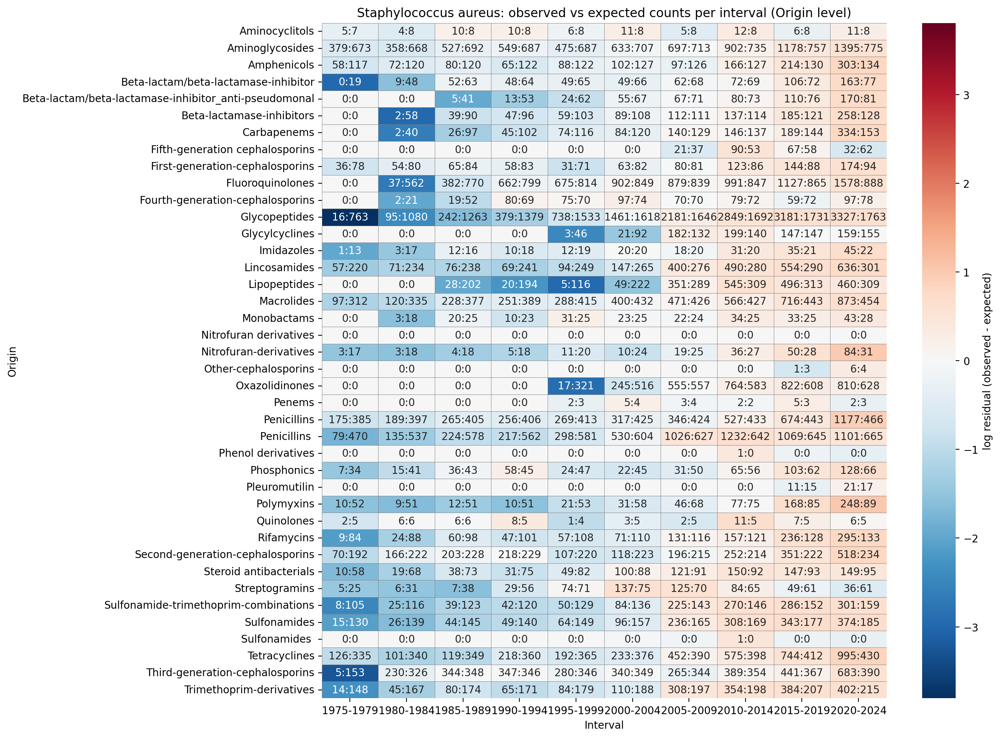

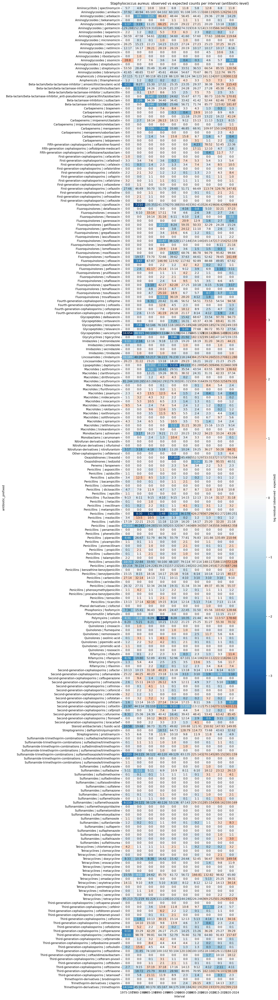

In [19]:
# Class-level heatmap
plot_heatmap_counts_vs_expected_class(
    marg_cl,
    pathogen,
    class_column='Origin',
    class_df=antibiotics_df,
    figsize=(14, 10)
)

# Antibiotic-level heatmap
plot_heatmap_counts_vs_expected_antibiotic(
    marg_ab,
    pathogen,
    class_df=antibiotics_df,
    figsize=(14, 50)
)



Sampled pathogen (log-weighted): Staphylococcus aureus


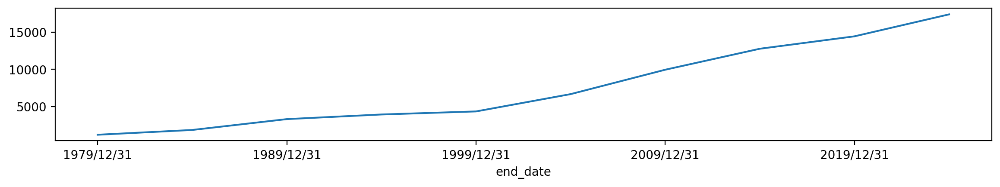

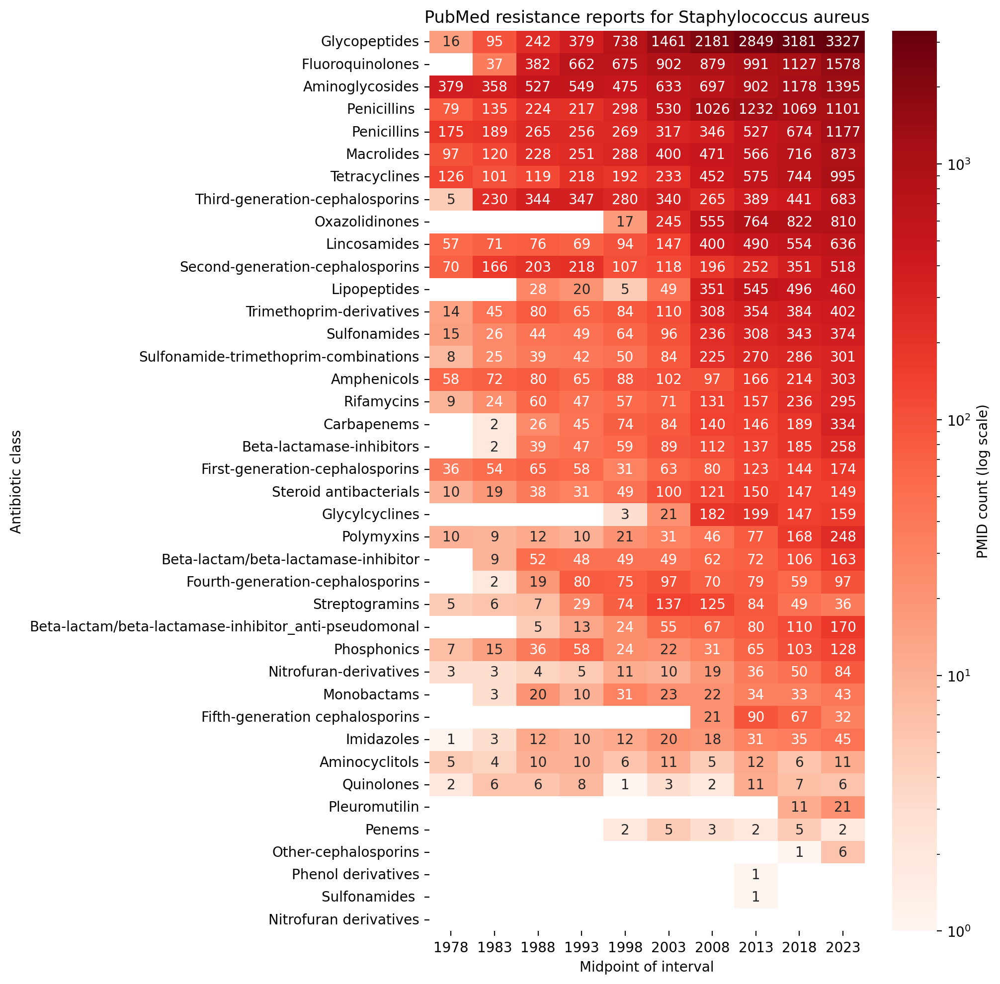

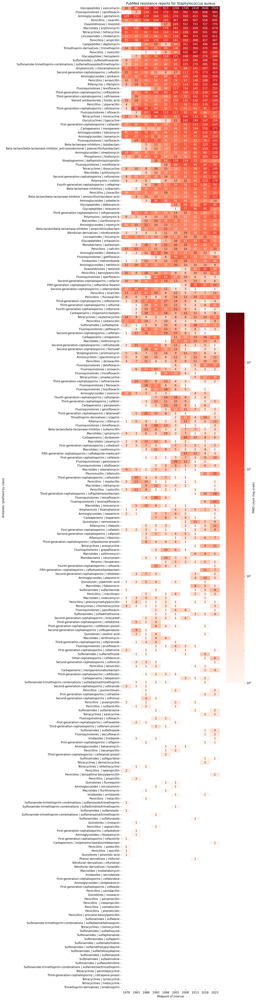

In [20]:
print(f"Sampled pathogen (log-weighted): {pathogen}")

# Plot heatmaps
df = amr_df[amr_df['pathogen'] == pathogen]
df.groupby('end_date')['count'].sum().plot(figsize=(14, 2))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=True, figsize=(10,10))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=False, figsize=(13,50))

---